In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

# Supports running from either the project root or notebooks/
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

In [2]:
PROJECT_ROOT = Path.cwd()

# Supports running from either the project root or notebooks/
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentage:
Machine failure
0    96.61
1     3.39
Name: count, dtype: float64


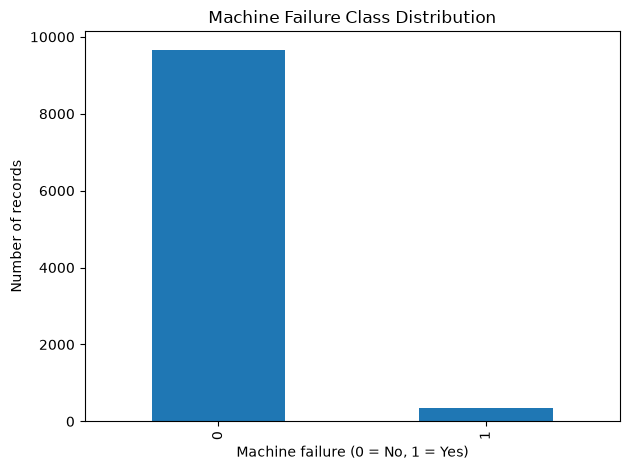

In [3]:
target = "Machine failure"

failure_counts = df[target].value_counts().sort_index()

print(failure_counts)
print("\nFailure percentage:")
print((failure_counts / len(df) * 100).round(2))

failure_counts.plot(
    kind="bar",
    xlabel="Machine failure (0 = No, 1 = Yes)",
    ylabel="Number of records",
    title="Machine Failure Class Distribution",
)

plt.tight_layout()
plt.show()

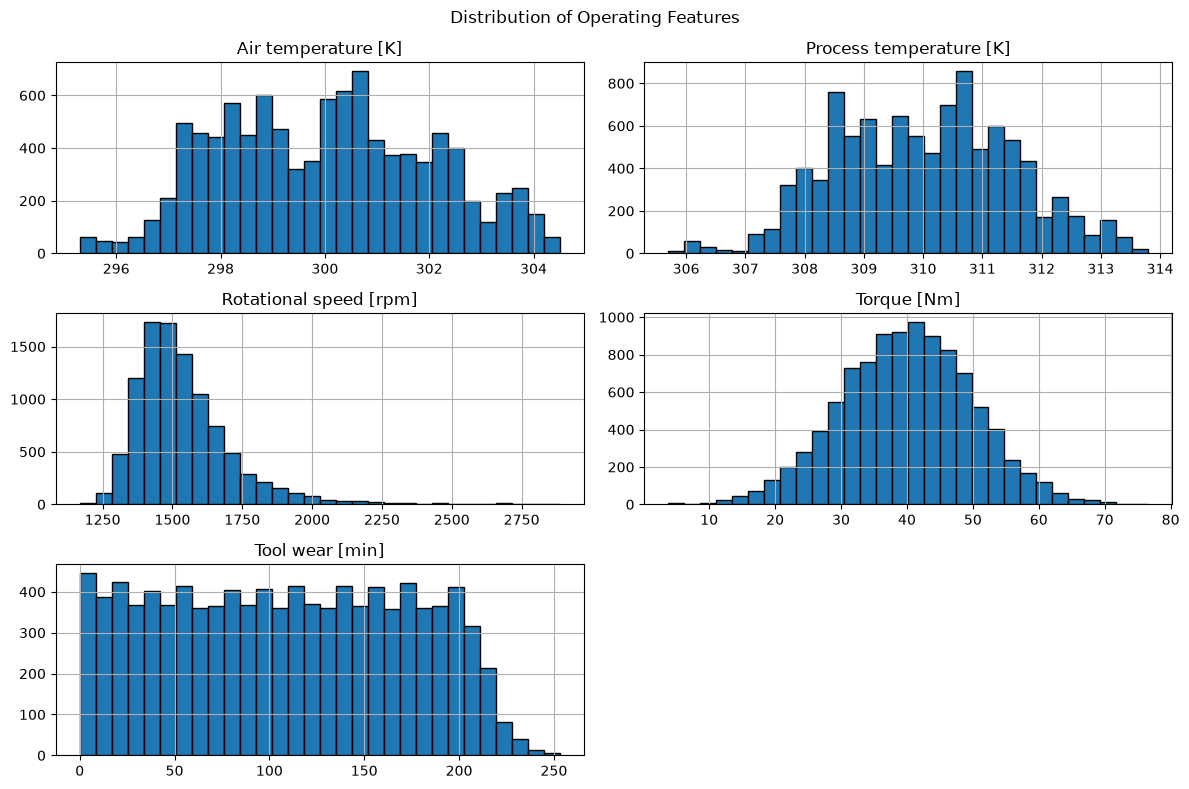

In [4]:
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

df[sensor_features].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black",
)

plt.suptitle("Distribution of Operating Features")
plt.tight_layout()
plt.show()

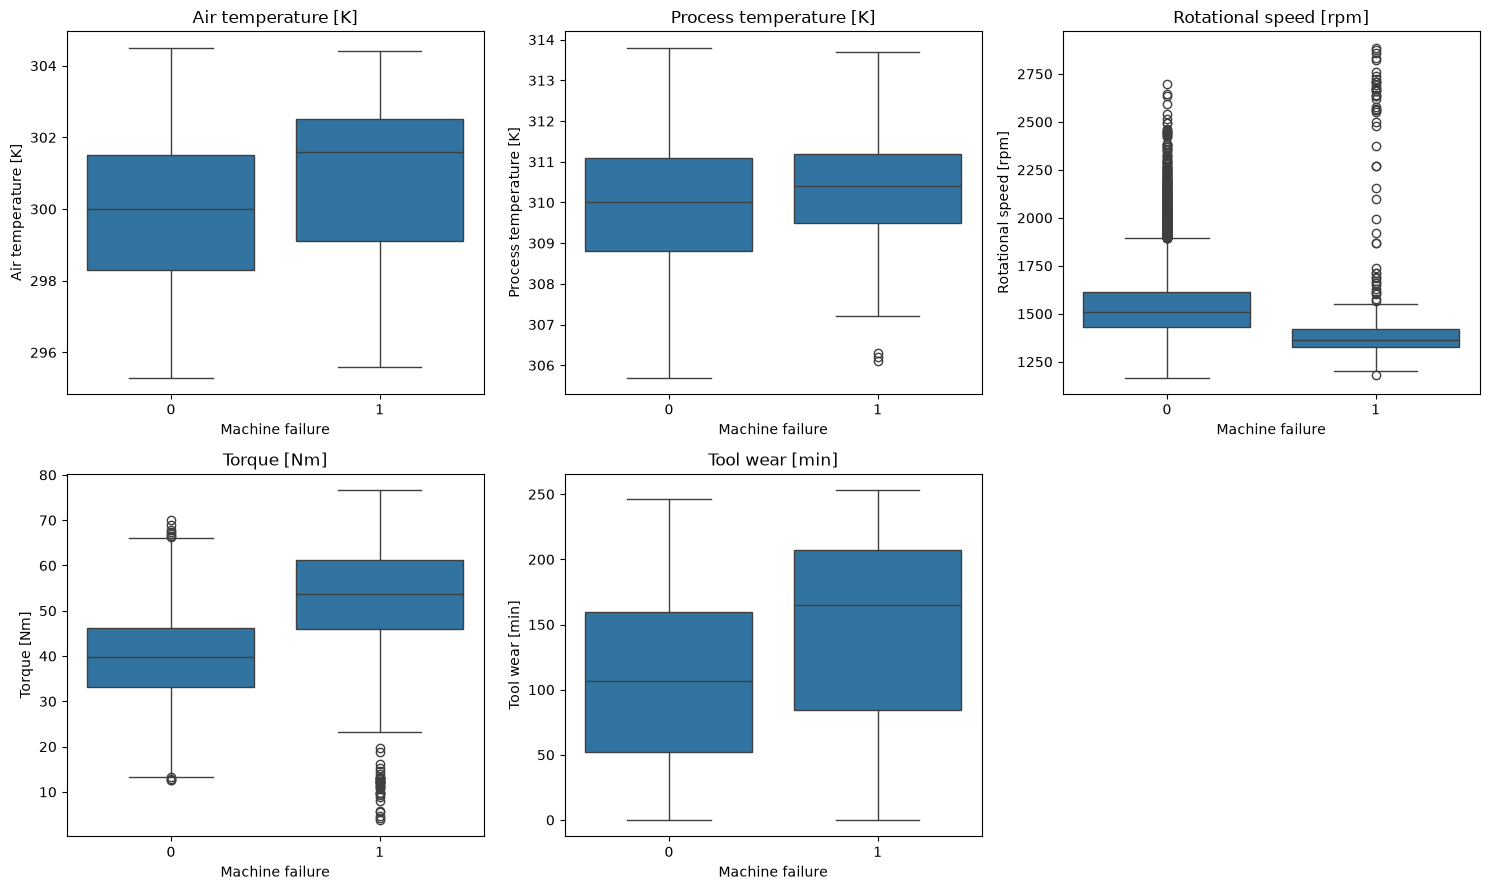

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feature in enumerate(sensor_features):
    sns.boxplot(
        data=df,
        x=target,
        y=feature,
        ax=axes[i],
    )
    axes[i].set_title(feature)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

TARGET = "Machine failure"

Machine failure          No Failure  Failure
Air temperature [K]          299.97   300.89
Process temperature [K]      310.00   310.29
Rotational speed [rpm]      1540.26  1496.49
Torque [Nm]                   39.63    50.17
Tool wear [min]              106.69   143.78


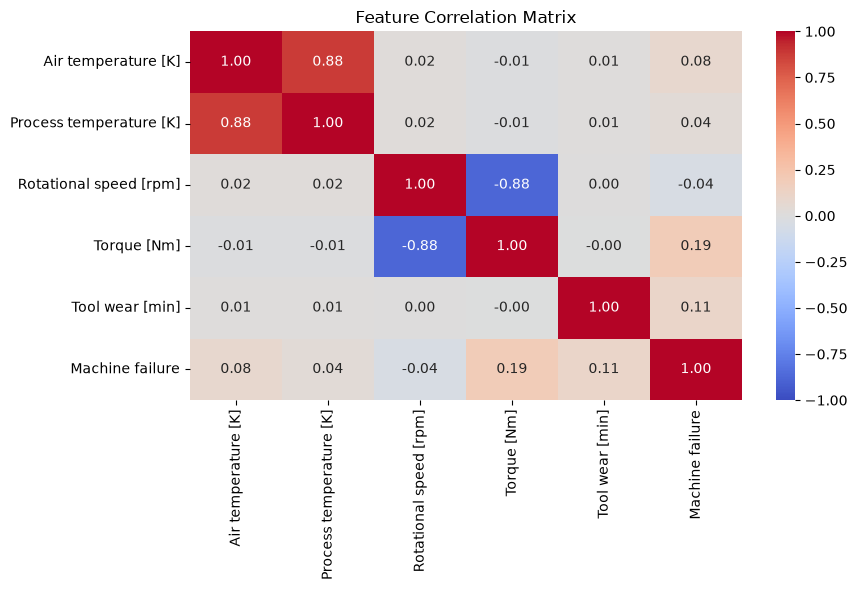

In [7]:
# Compare numeric features with the failure target
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

print(
    df.groupby("Machine failure")[numeric_features]
      .mean()
      .T
      .rename(columns={0: "No Failure", 1: "Failure"})
      .round(2)
)

# Correlation among numeric operating features
plt.figure(figsize=(9, 6))

sns.heatmap(
    df[numeric_features + ["Machine failure"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()